# 04 – Calibration: Can We Trust the Risk Scores as Probabilities?

> **Project notebooks:** [01 Exploration](01_exploration.ipynb) · [02 First model](02_first_model.ipynb) · [03 Tuning and blending](03_tuning_and_blending.ipynb) · [04 Calibration](04_calibration.ipynb) · [05 Explanation and fairness](05_explanation_and_fairness.ipynb)

Kaggle's ROC AUC only looks at the **ranking** of borrowers: who is riskier than whom. A bank needs more than a ranking. It needs to know that when the model says **"10% risk"**, about 10 out of 100 such borrowers really get into trouble. A model with that property is called **well calibrated**.

**Why it matters**

| Use | Needs real probabilities because … |
|---|---|
| **The decision threshold** (notebook 02) | the rule "reject above 17%" was derived for real probabilities |
| **Interest rates** | riskier borrowers pay more; the price is based on the probability of default |
| **Planning for losses** | the bank must set money aside for expected defaults: the *sum* of all probabilities |

**Contents**
1. Setup
2. The calibration curve
3. A popular trick for rare events, and how it breaks the probabilities
4. What broken probabilities cost
5. Repairing the probabilities
6. Planning for losses
7. Conclusions

## 1. Setup

In [1]:
import sys
sys.path.append("..")   # the project folder, where src/ lives

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import brier_score_loss, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from xgboost import XGBClassifier

from src.features import CreditFeatures, TARGET, load

warnings.filterwarnings("ignore", category=FutureWarning)  # hide a harmless seaborn/pandas version notice
sns.set_theme(style="whitegrid", palette="Set2")

df = load("../data/cs-training.csv")
test_raw = load("../data/cs-test.csv")
y = df[TARGET].to_numpy()
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Best settings from notebook 03
HGB_SETTINGS = dict(learning_rate=0.02, max_iter=800, max_leaf_nodes=31, min_samples_leaf=20,
                    l2_regularization=1, random_state=42)
hgb = make_pipeline(CreditFeatures(), HistGradientBoostingClassifier(**HGB_SETTINGS))
xgb = make_pipeline(CreditFeatures(), XGBClassifier(learning_rate=0.05, n_estimators=300, max_depth=4, min_child_weight=1,
                                                    subsample=0.8, colsample_bytree=0.8, eval_metric="auc",
                                                    tree_method="hist", n_jobs=1, random_state=42))


def cv_probabilities(model):
    return cross_val_predict(model, df, y, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]


probabilities = {"Blend (notebook 03)": (cv_probabilities(hgb) + cv_probabilities(xgb)) / 2}
print(f"Blend: ROC AUC {roc_auc_score(y, probabilities['Blend (notebook 03)']):.4f}")

Blend: ROC AUC 0.8664


## 2. The calibration curve

The test is simple. Sort the borrowers by their predicted risk, split them into ten equally large groups, and compare in each group:

- the **average predicted** risk, with
- the **actual** share of defaulters.

If the model is well calibrated, the two are equal and the points lie on the diagonal. This chart is called a **calibration curve** or **reliability diagram**.

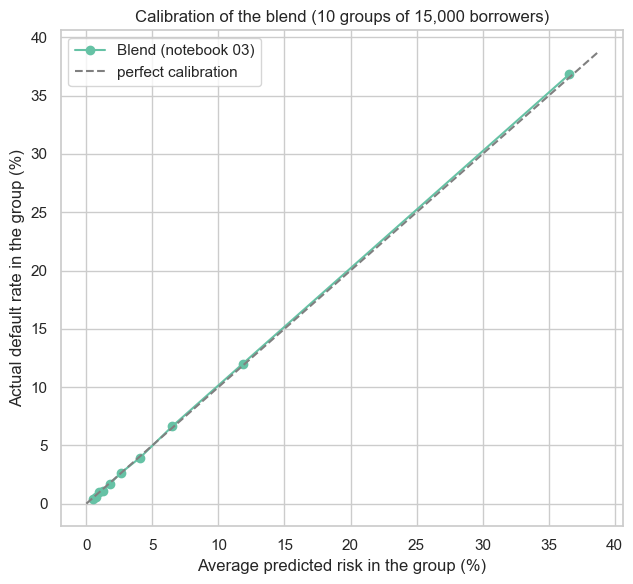

risk group,1,2,3,4,5,6,7,8,9,10
predicted risk (%),0.5,0.7,0.9,1.3,1.8,2.6,4.0,6.5,11.8,36.6
actual default rate (%),0.4,0.6,1.0,1.1,1.7,2.7,3.9,6.7,12.0,36.8


In [2]:
def plot_calibration(ax, names, title):
    for name in names:
        actual, predicted = calibration_curve(y, probabilities[name], n_bins=10, strategy="quantile")
        ax.plot(predicted * 100, actual * 100, marker="o", label=name)
    limit = max(ax.get_xlim()[1], ax.get_ylim()[1])
    ax.plot([0, limit], [0, limit], color="grey", linestyle="--", label="perfect calibration")
    ax.set(title=title, xlabel="Average predicted risk in the group (%)", ylabel="Actual default rate in the group (%)")
    ax.legend()


fig, ax = plt.subplots(figsize=(6.5, 6))
plot_calibration(ax, ["Blend (notebook 03)"], "Calibration of the blend (10 groups of 15,000 borrowers)")
plt.tight_layout()
plt.savefig("../images/calibration_blend.png", dpi=120)
plt.show()

actual, predicted = calibration_curve(y, probabilities["Blend (notebook 03)"], n_bins=10, strategy="quantile")
pd.DataFrame({"predicted risk (%)": predicted * 100, "actual default rate (%)": actual * 100},
             index=pd.Index(range(1, 11), name="risk group")).round(1).T

The points lie almost exactly on the diagonal. In the riskiest group, the model predicts on average 36.6% and 36.8% actually defaulted; in the safest group, 0.5% predicted and 0.4% actual.

**Our model is well calibrated.** That is not luck: gradient boosting is trained by minimising the **log loss**, which rewards honest probabilities. So the 17% threshold from notebook 02 can be trusted.

A single number for calibration is the **Brier score**: the average squared difference between the predicted probability and the outcome (0 or 1). Lower is better. Unlike ROC AUC, it punishes probabilities that are too high or too low, even if the ranking is perfect.

In [3]:
print(f"Brier score of the blend:                        {brier_score_loss(y, probabilities['Blend (notebook 03)']):.4f}")
print(f"Brier score of 'everyone gets the average risk': {brier_score_loss(y, np.full(len(y), y.mean())):.4f}")

Brier score of the blend:                        0.0488
Brier score of 'everyone gets the average risk': 0.0624


## 3. A popular trick for rare events, and how it breaks the probabilities

A very common piece of advice for imbalanced data is to **re‑weight the classes**: tell the model that every defaulter counts as much as about 14 non‑defaulters, so that both classes have equal total weight. In scikit‑learn this is one setting, `class_weight="balanced"`. The same idea is behind **oversampling** (copying defaulters) and **undersampling** (removing non‑defaulters).

Let's train the same tuned gradient boosting model with balanced class weights:

In [4]:
%%time
balanced = make_pipeline(CreditFeatures(), HistGradientBoostingClassifier(class_weight="balanced", **HGB_SETTINGS))
probabilities["Balanced class weights"] = cv_probabilities(balanced)

for name in probabilities:
    p = probabilities[name]
    print(f"{name:<24} ROC AUC {roc_auc_score(y, p):.4f}   average predicted risk {p.mean():6.1%}   "
          f"Brier {brier_score_loss(y, p):.4f}")
print(f"{'Reality':<24} {'':16}   share of defaulters    {y.mean():6.1%}")

Blend (notebook 03)      ROC AUC 0.8664   average predicted risk   6.7%   Brier 0.0488
Balanced class weights   ROC AUC 0.8648   average predicted risk  31.8%   Brier 0.1411
Reality                                     share of defaulters      6.7%
CPU times: user 330 ms, sys: 454 ms, total: 784 ms
Wall time: 4.86 s


The **ROC AUC is practically unchanged** (0.865). If we only looked at Kaggle's measure, we would think nothing happened.

But the model now predicts an **average risk of about 32%**, while only 6.7% of borrowers default: almost **five times too high**. The Brier score is three times worse. The re‑weighting told the model that defaulters are as common as non‑defaulters, and it believed it.

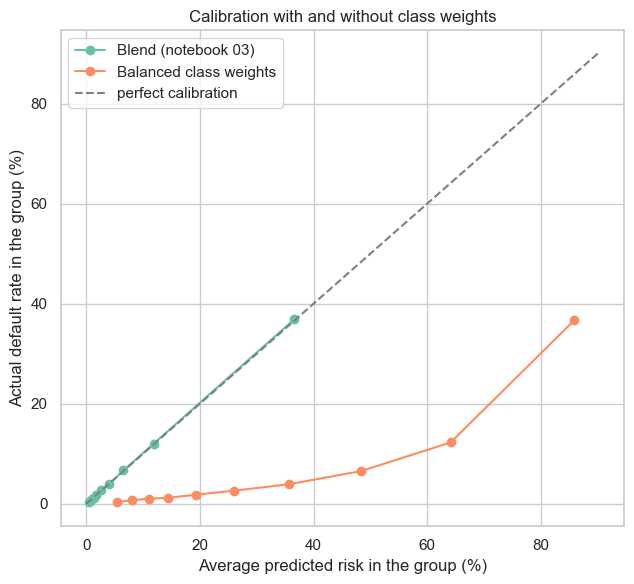

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 6))
plot_calibration(ax, ["Blend (notebook 03)", "Balanced class weights"], "Calibration with and without class weights")
plt.tight_layout()
plt.savefig("../images/calibration_balanced.png", dpi=120)
plt.show()

The balanced model's curve lies far **below** the diagonal: it predicts much more risk than there really is. In its riskiest group it predicts about 86% and only 37% default. In its safest group it predicts 5% where 0.3% default.

The **order** of the borrowers is almost the same as before, which is why the AUC did not change. Only the **numbers** are wrong.

## 4. What broken probabilities cost

Suppose a colleague takes the balanced model and applies the rule from notebook 02, *"reject above 17% risk"*, which assumes real probabilities. With the same illustrative costs (\$5,000 per missed defaulter, \$1,000 per rejected good borrower):

In [6]:
COST_MISSED_DEFAULTER, COST_REJECTED_GOOD = 5_000, 1_000


def cost_of(p, threshold):
    missed = ((p < threshold) & (y == 1)).sum()
    rejected_good = ((p >= threshold) & (y == 0)).sum()
    return (missed * COST_MISSED_DEFAULTER + rejected_good * COST_REJECTED_GOOD) / 1e6


thresholds = np.round(np.arange(0.02, 0.99, 0.01), 2)
rows = []
for name in ["Blend (notebook 03)", "Balanced class weights"]:
    p = probabilities[name]
    best = thresholds[np.argmin([cost_of(p, t) for t in thresholds])]
    rows.append({"model": name, "applicants rejected at 17%": (p >= 0.17).mean(),
                 "cost at 17% ($m)": cost_of(p, 0.17), "cheapest threshold": best,
                 "cost at cheapest threshold ($m)": cost_of(p, best)})
pd.DataFrame(rows).set_index("model").style.format({
    "applicants rejected at 17%": "{:.0%}", "cost at 17% ($m)": "{:.1f}",
    "cheapest threshold": "{:.0%}", "cost at cheapest threshold ($m)": "{:.1f}"})

,applicants rejected at 17%,cost at 17% ($m),cheapest threshold,cost at cheapest threshold ($m)
model,,,,
Blend (notebook 03),10%,31.9,15%,31.9
Balanced class weights,59%,81.7,73%,31.9


With the balanced model, the 17% rule rejects **59%** of all applicants and the cost of mistakes jumps from \$32 million to about **\$82 million**, two and a half times as much.

The model is not bad: at *its own* cheapest threshold (73%), it costs the same \$32 million as the blend. (For the blend, the cheapest threshold here is 15%, which costs the same as 17%: the cost curve is flat around its minimum.) The problem is that its numbers no longer **mean** what they say, so every rule, price or plan built on them is wrong. And nothing in the AUC warned us.

**Lesson:** re‑weighting or resampling changes the probabilities. It is often unnecessary for models like gradient boosting, which handle imbalance well by themselves. If you use it, you must repair the probabilities afterwards.

## 5. Repairing the probabilities

`CalibratedClassifierCV` learns a translation from the model's scores to real probabilities. With `method="isotonic"` it fits a step‑shaped curve that maps, say, "86%" back to "37%". To avoid leakage it learns that translation on data the model was not trained on: here an internal 3‑fold split inside each training fold.

ROC AUC 0.8651, average predicted risk 6.7%, Brier 0.0491, cost at 17%: $32.0m


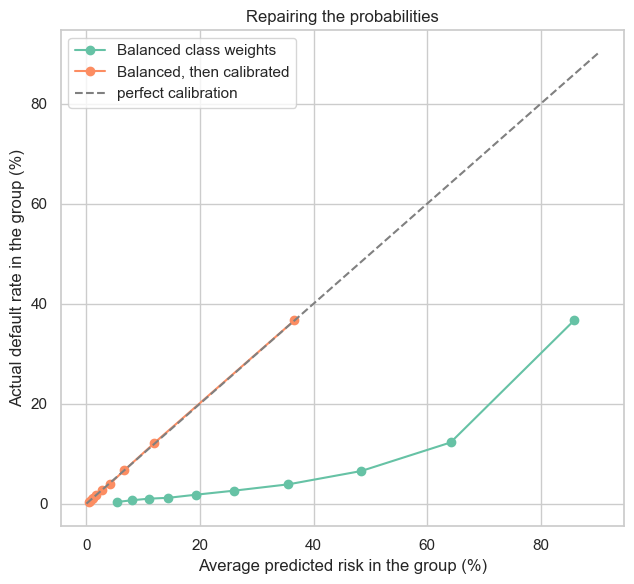

CPU times: user 527 ms, sys: 15.9 ms, total: 543 ms
Wall time: 9.19 s


In [7]:
%%time
repaired = make_pipeline(CreditFeatures(), CalibratedClassifierCV(
    HistGradientBoostingClassifier(class_weight="balanced", **HGB_SETTINGS), method="isotonic", cv=3))
probabilities["Balanced, then calibrated"] = cv_probabilities(repaired)

p = probabilities["Balanced, then calibrated"]
print(f"ROC AUC {roc_auc_score(y, p):.4f}, average predicted risk {p.mean():.1%}, Brier {brier_score_loss(y, p):.4f}, "
      f"cost at 17%: ${cost_of(p, 0.17):.1f}m")

fig, ax = plt.subplots(figsize=(6.5, 6))
plot_calibration(ax, ["Balanced class weights", "Balanced, then calibrated"], "Repairing the probabilities")
plt.tight_layout()
plt.show()

After calibration the probabilities are honest again: average predicted risk 6.7%, the curve back on the diagonal, and the 17% rule costs \$32 million again. The ranking, and so the AUC, stays the same.

The cleanest solution, though, is the one we had from the start: **do not re‑weight** when the model does not need it. Our blend was well calibrated without any repair.

## 6. Planning for losses

Well‑calibrated probabilities can be **added up**. The sum of all predicted probabilities is the expected number of defaulters, which is what a bank uses to set money aside for future losses.

First a check on the training data (out‑of‑fold), then the 101,503 new applicants in `cs-test.csv`:

In [8]:
blend_p = probabilities["Blend (notebook 03)"]
print(f"Training data: expected defaulters {blend_p.sum():,.0f}, actual defaulters {y.sum():,}")
print(f"Balanced model would have expected {probabilities['Balanced class weights'].sum():,.0f}")

hgb.fit(df, y)
xgb.fit(df, y)
test_p = (hgb.predict_proba(test_raw)[:, 1] + xgb.predict_proba(test_raw)[:, 1]) / 2
print(f"\nNew applicants: expected defaulters {test_p.sum():,.0f} of {len(test_p):,} ({test_p.mean():.1%})")
print(f"Expected loss at $5,000 per defaulter if all were approved: ${test_p.sum() * COST_MISSED_DEFAULTER / 1e6:,.1f} million")

Training data: expected defaulters 10,015, actual defaulters 10,026
Balanced model would have expected 47,729

New applicants: expected defaulters 6,797 of 101,503 (6.7%)
Expected loss at $5,000 per defaulter if all were approved: $34.0 million


On the training data the blend expects 10,015 defaulters, and there were 10,026: almost exactly right. The balanced model would have expected about 47,700. For the new applicants it expects about 6.7% to default (6,797 of 101,503), and the bank could plan its reserves on that basis. The balanced model would have told the bank to prepare for almost five times as many defaults.

(Expected numbers like this only hold if the new applicants are similar to the old ones. If the economy changes, the probabilities must be checked again.)

## 7. Conclusions

| Model | ROC AUC | Average predicted risk | Brier score | Cost with the 17% rule |
|---|---|---|---|---|
| Blend (notebook 03) | 0.866 | 6.7% | 0.049 | \$32m |
| Balanced class weights | 0.865 | **32%** | 0.141 | **\$82m** |
| Balanced, then calibrated | 0.865 | 6.7% | 0.049 | \$32m |

**What we learned**

| Concept | In one sentence |
|---|---|
| **Calibration** | A model is calibrated when "10% risk" really means 10 defaulters out of 100. |
| **Calibration curve** | Predicted vs. actual rate in groups; points on the diagonal mean honest probabilities. |
| **Brier score** | One number for how honest the probabilities are; AUC cannot see it. |
| **Class weights and resampling** | They leave the ranking almost unchanged but distort the probabilities. |
| **`CalibratedClassifierCV`** | Learns a translation back to real probabilities, without leakage. |
| **Expected loss** | Calibrated probabilities can be summed to plan for future defaults. |

**The key lesson:** a model can have an excellent AUC and still give numbers that are badly wrong. When decisions, prices or plans depend on the probabilities, always check the calibration curve, not just the AUC.